In [76]:
# ===============================
# Spotify Song Popularity Prediction
# Import Required Libraries
# ===============================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning Libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Ignore warning messages
import warnings
warnings.filterwarnings("ignore")

# Plot style
plt.style.use("ggplot")

print("All required libraries imported successfully.")


All required libraries imported successfully.


In [77]:
# ===============================
# Load the Dataset
# ===============================

# Read the CSV file
df = pd.read_csv("songs_normalize.csv")

print("Dataset loaded successfully!")

# Display first 5 rows
df.head()

Dataset loaded successfully!


,artist,song,duration_ms,explicit,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,genre
0,Britney Spears,Oops!...I Did It Again,211160,False,2000,77,0.751,0.834,1,-5.444,0,0.0437,0.3000,0.000018,0.3550,0.894,95.053,pop
1,blink-182,All The Small Things,167066,False,1999,79,0.434,0.897,0,-4.918,1,0.0488,0.0103,0.000000,0.6120,0.684,148.726,"rock, pop"
2,Faith Hill,Breathe,250546,False,1999,66,0.529,0.496,7,-9.007,1,0.0290,0.1730,0.000000,0.2510,0.278,136.859,"pop, country"
3,Bon Jovi,It's My Life,224493,False,2000,78,0.551,0.913,0,-4.063,0,0.0466,0.0263,0.000013,0.3470,0.544,119.992,"rock, metal"
4,*NSYNC,Bye Bye Bye,200560,False,2000,65,0.614,0.928,8,-4.806,0,0.0516,0.0408,0.001040,0.0845,0.879,172.656,pop


In [78]:
# ===============================
# Basic Information about Dataset
# ===============================

# Dataset dimensions
rows, cols = df.shape

print(f"Number of Rows    : {rows}")
print(f"Number of Columns : {cols}")

# Display column names
print("\nColumn Names:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Number of Rows    : 2000
Number of Columns : 18

Column Names:
1. artist
2. song
3. duration_ms
4. explicit
5. year
6. popularity
7. danceability
8. energy
9. key
10. loudness
11. mode
12. speechiness
13. acousticness
14. instrumentalness
15. liveness
16. valence
17. tempo
18. genre


In [79]:
# ===============================
# Dataset Information
# ===============================

print("Dataset Information:\n")
df.info()

Dataset Information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   artist            2000 non-null   object 
 1   song              2000 non-null   object 
 2   duration_ms       2000 non-null   int64  
 3   explicit          2000 non-null   bool   
 4   year              2000 non-null   int64  
 5   popularity        2000 non-null   int64  
 6   danceability      2000 non-null   float64
 7   energy            2000 non-null   float64
 8   key               2000 non-null   int64  
 9   loudness          2000 non-null   float64
 10  mode              2000 non-null   int64  
 11  speechiness       2000 non-null   float64
 12  acousticness      2000 non-null   float64
 13  instrumentalness  2000 non-null   float64
 14  liveness          2000 non-null   float64
 15  valence           2000 non-null   float64
 16  tempo             20

In [80]:
# ===============================
# Statistical Summary
# ===============================

df.describe().T

,count,mean,std,min,25%,50%,75%,max
duration_ms,2000.0,228748.124500,39136.569008,113000.000000,203580.00000,223279.50000,248133.000000,484146.000
year,2000.0,2009.494000,5.859960,1998.000000,2004.00000,2010.00000,2015.000000,2020.000
popularity,2000.0,59.872500,21.335577,0.000000,56.00000,65.50000,73.000000,89.000
danceability,2000.0,0.667438,0.140416,0.129000,0.58100,0.67600,0.764000,0.975
energy,2000.0,0.720366,0.152745,0.054900,0.62200,0.73600,0.839000,0.999
key,2000.0,5.378000,3.615059,0.000000,2.00000,6.00000,8.000000,11.000
loudness,2000.0,-5.512434,1.933482,-20.514000,-6.49025,-5.28500,-4.167750,-0.276
mode,2000.0,0.553500,0.497254,0.000000,0.00000,1.00000,1.000000,1.000
speechiness,2000.0,0.103568,0.096159,0.023200,0.03960,0.05985,0.129000,0.576
acousticness,2000.0,0.128955,0.173346,0.000019,0.01400,0.05570,0.176250,0.976


In [81]:
# ===============================
# Check Missing Values
# ===============================

missing_values = df.isnull().sum()

print("Missing Values in Each Column:\n")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values in Each Column:

artist              0
song                0
duration_ms         0
explicit            0
year                0
popularity          0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
genre               0
dtype: int64

Total Missing Values: 0


In [82]:
# ===============================
# Check Duplicate Records
# ===============================

duplicate_rows = df.duplicated().sum()

print(f"Number of Duplicate Rows: {duplicate_rows}")

Number of Duplicate Rows: 59


In [83]:
# ===============================
# Remove Duplicate Records
# ===============================

df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:")
print(df.shape)

Dataset Shape After Removing Duplicates:
(1941, 18)


In [84]:
# ===============================
# Check Data Types
# ===============================

df.dtypes

artist               object
song                 object
duration_ms           int64
explicit               bool
year                  int64
popularity            int64
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
genre                object
dtype: object

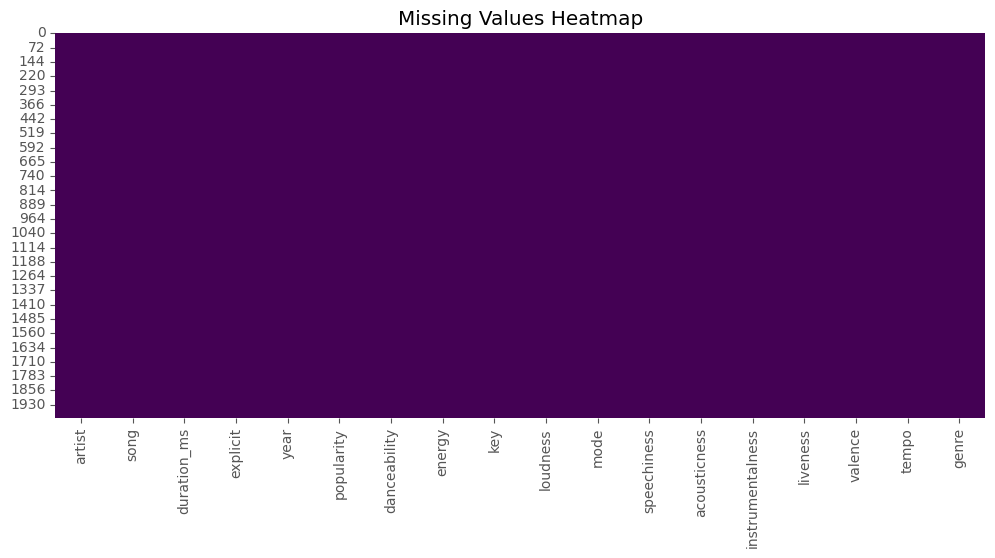

In [85]:
# ===============================
# Missing Value Visualization
# ===============================

plt.figure(figsize=(12,5))

sns.heatmap(df.isnull(),
            cbar=False,
            cmap="viridis")

plt.title("Missing Values Heatmap")
plt.show()

In [86]:
features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "duration_ms",
    "key",
    "mode",
    "explicit",
    "year"
]

In [87]:
# ===============================
# Create Popularity Categories
# ===============================

def popularity_category(score):

    if score >= 70:
        return "Popular"

    elif score >= 40:
        return "Moderately Popular"

    else:
        return "Not Popular"

df["popularity_category"] = df["popularity"].apply(popularity_category)

df[["popularity","popularity_category"]].head()

,popularity,popularity_category
0,77,Popular
1,79,Popular
2,66,Moderately Popular
3,78,Popular
4,65,Moderately Popular


In [88]:
# ===============================
# Popularity Category Distribution
# ===============================

category_count = df["popularity_category"].value_counts()

print(category_count)

print("\nPercentage Distribution\n")

print((category_count/len(df))*100)

popularity_category
Moderately Popular    1026
Popular                699
Not Popular            216
Name: count, dtype: int64

Percentage Distribution

popularity_category
Moderately Popular    52.859351
Popular               36.012365
Not Popular           11.128284
Name: count, dtype: float64


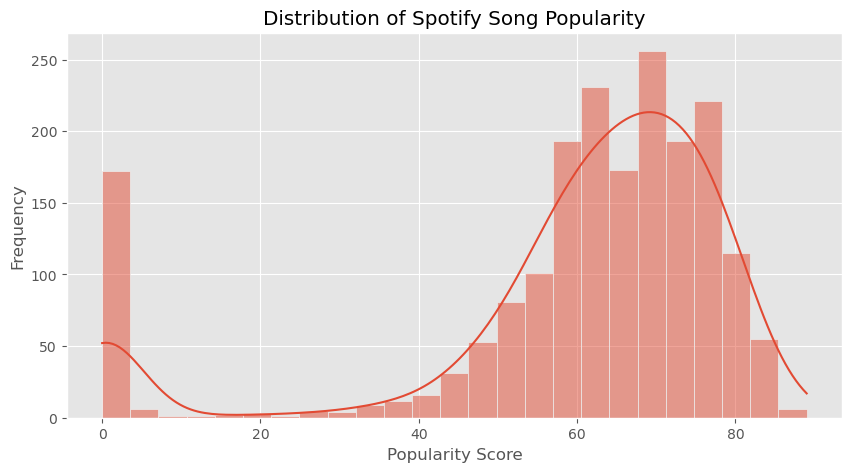

In [89]:
# ===============================
# Popularity Distribution
# ===============================

plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x="popularity",
    bins=25,
    kde=True
)

plt.title("Distribution of Spotify Song Popularity")
plt.xlabel("Popularity Score")
plt.ylabel("Frequency")

plt.show()

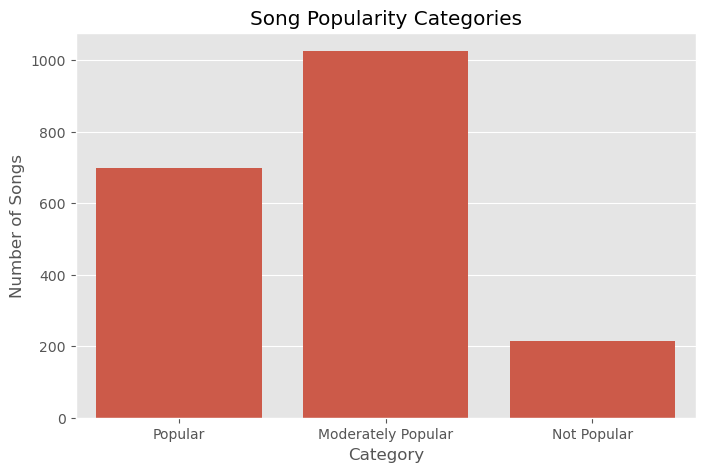

In [90]:
# ===============================
# Popularity Class Count
# ===============================

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="popularity_category"
)

plt.title("Song Popularity Categories")
plt.xlabel("Category")
plt.ylabel("Number of Songs")


plt.show()

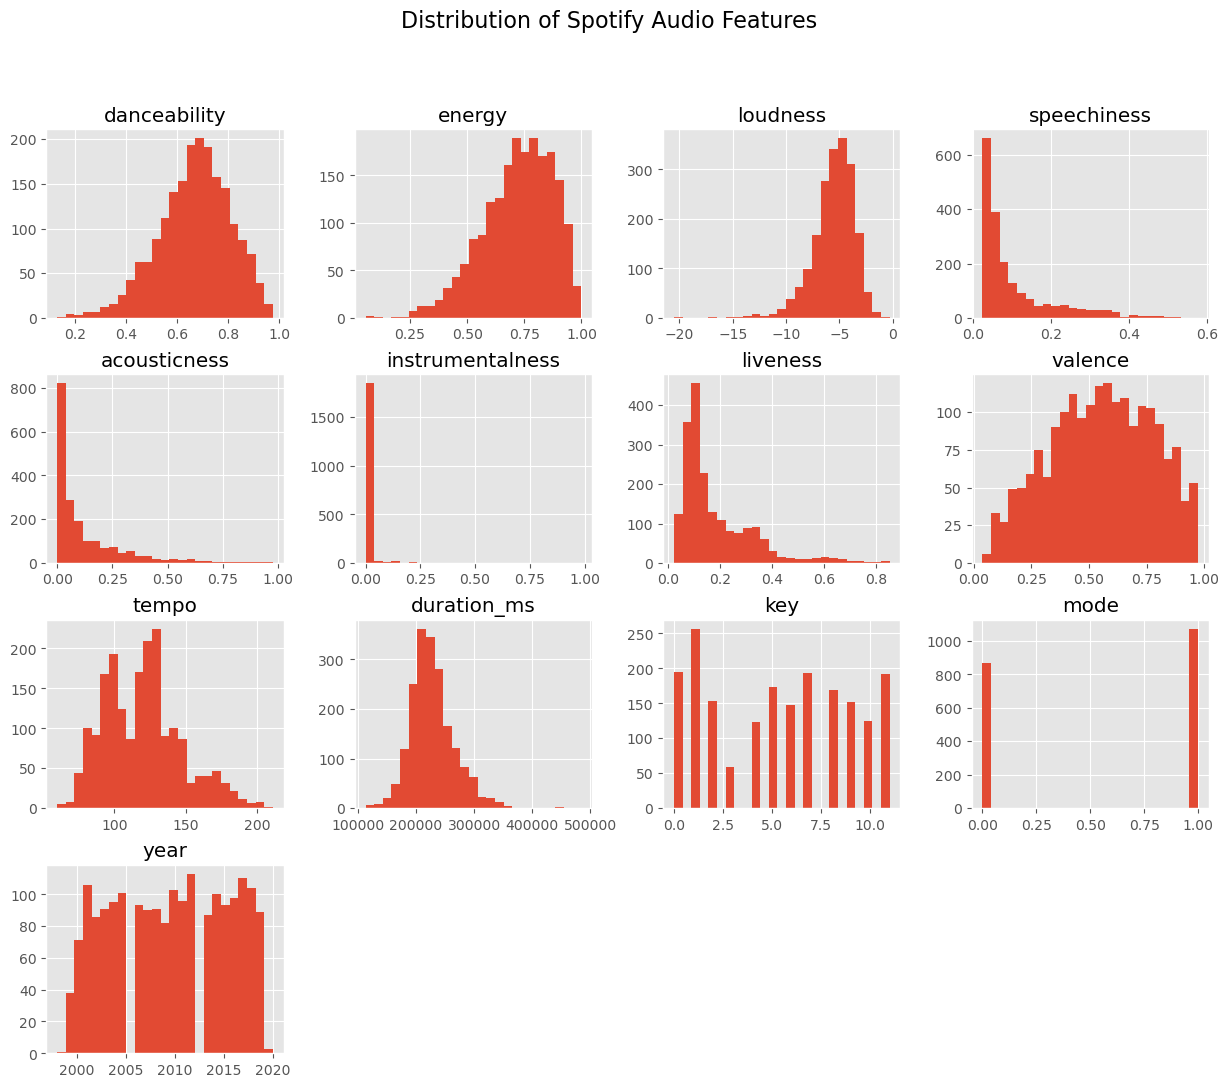

In [91]:
# ===============================
# Distribution of Audio Features
# ===============================

df[features].hist(
    figsize=(15,12),
    bins=25
)

plt.suptitle("Distribution of Spotify Audio Features",fontsize=16)

plt.show()

In [92]:
# ===============================
# Encode Target Labels
# ===============================

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df["popularity_category"] = label_encoder.fit_transform(
    df["popularity_category"]
)

print("Encoded Classes:")
for label, value in zip(label_encoder.classes_,
                        label_encoder.transform(label_encoder.classes_)):
    print(f"{label} --> {value}")

Encoded Classes:
Moderately Popular --> 0
Not Popular --> 1
Popular --> 2


In [93]:
# ===============================
# Define Features and Target
# ===============================

X = df[features]

y = df["popularity_category"]

print("Feature Shape :", X.shape)
print("Target Shape  :", y.shape)

Feature Shape : (1941, 14)
Target Shape  : (1941,)


In [94]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training Samples:", len(X_train))
print("Testing Samples :", len(X_test))

Training Samples: 1552
Testing Samples : 389


In [95]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=500,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Model Trained Successfully!")

Model Trained Successfully!


In [96]:
y_pred = model.predict(X_test)

print("Prediction Completed!")

Prediction Completed!


In [97]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy : {accuracy*100:.2f}%")

Model Accuracy : 53.47%


In [98]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.60      0.74      0.67       206
           1       0.20      0.05      0.08        43
           2       0.42      0.38      0.40       140

    accuracy                           0.53       389
   macro avg       0.41      0.39      0.38       389
weighted avg       0.49      0.53      0.50       389



In [99]:
# ===============================
# Classification Report
# ===============================

from sklearn.metrics import classification_report

print("Classification Report\n")
print(classification_report(y_test, y_pred))

Classification Report

              precision    recall  f1-score   support

           0       0.60      0.74      0.67       206
           1       0.20      0.05      0.08        43
           2       0.42      0.38      0.40       140

    accuracy                           0.53       389
   macro avg       0.41      0.39      0.38       389
weighted avg       0.49      0.53      0.50       389



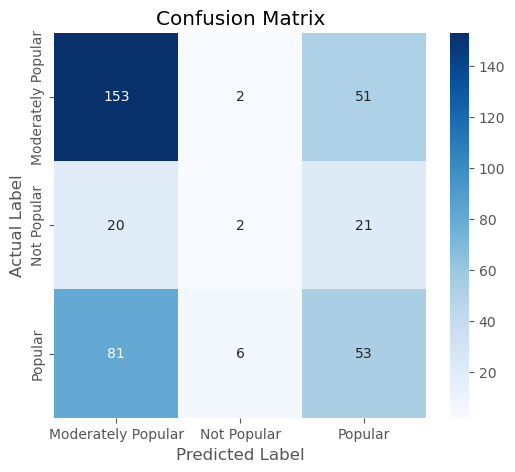

In [100]:
# ===============================
# Confusion Matrix
# ===============================

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")

plt.show()

In [101]:
# ===============================
# Feature Importance
# ===============================

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance

,Feature,Importance
13,year,0.131172
9,duration_ms,0.091838
8,tempo,0.090783
1,energy,0.088117
2,loudness,0.083948
0,danceability,0.081068
6,liveness,0.081065
7,valence,0.080941
4,acousticness,0.078254
3,speechiness,0.075623


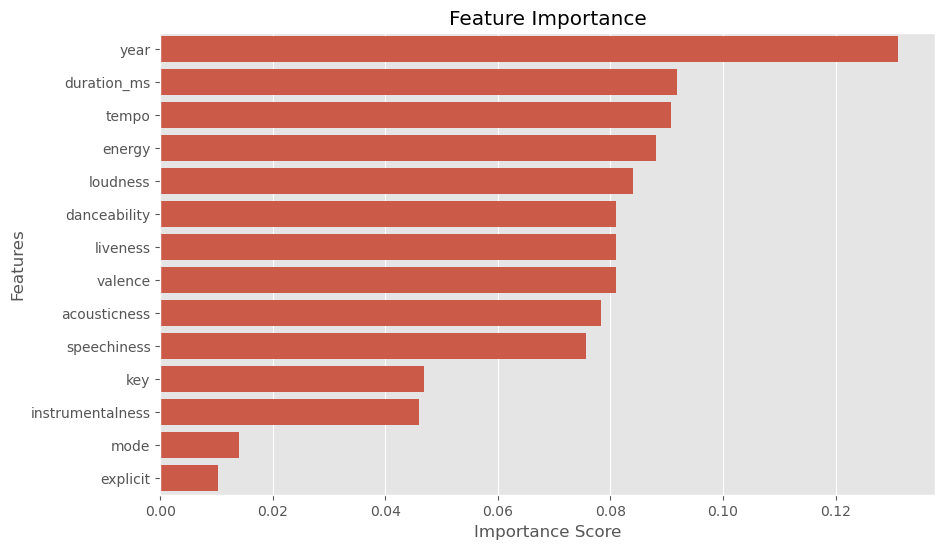

In [102]:
# ===============================
# Feature Importance Plot
# ===============================

plt.figure(figsize=(10,6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()

In [103]:
# ===============================
# Save Trained Model
# ===============================

import joblib

joblib.dump(model, "spotify_popularity_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [105]:
import joblib

loaded_model = joblib.load("spotify_popularity_model.pkl")

print("Model loaded successfully!")

Model loaded successfully!


In [109]:
sample_song = pd.DataFrame([{
    "danceability": 0.75,
    "energy": 0.82,
    "loudness": -5.4,
    "speechiness": 0.05,
    "acousticness": 0.12,
    "instrumentalness": 0.00,
    "liveness": 0.18,
    "valence": 0.72,
    "tempo": 120,
    "duration_ms": 210000,
    "key": 5,
    "mode": 1,
    "explicit": 0,
    "year": 2023
}])

In [110]:
prediction = loaded_model.predict(sample_song)

print("Prediction:", prediction)

print("Predicted Category:",
      label_encoder.inverse_transform(prediction)[0])

Prediction: [2]
Predicted Category: Popular


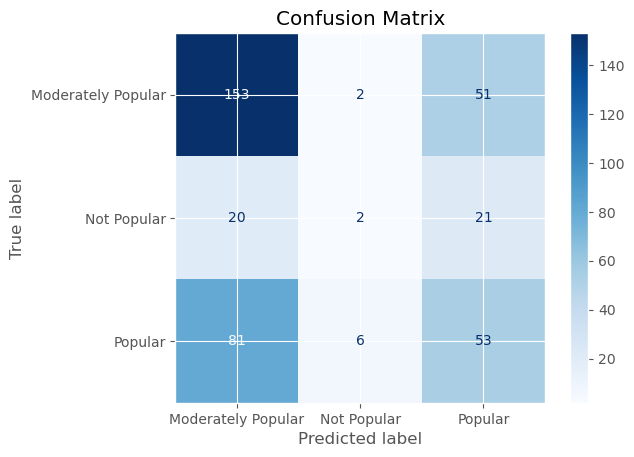

In [111]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=label_encoder.classes_)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [112]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

             Feature  Importance
13              year    0.131172
9        duration_ms    0.091838
8              tempo    0.090783
1             energy    0.088117
2           loudness    0.083948
0       danceability    0.081068
6           liveness    0.081065
7            valence    0.080941
4       acousticness    0.078254
3        speechiness    0.075623
10               key    0.046948
5   instrumentalness    0.046013
11              mode    0.013940
12          explicit    0.010290


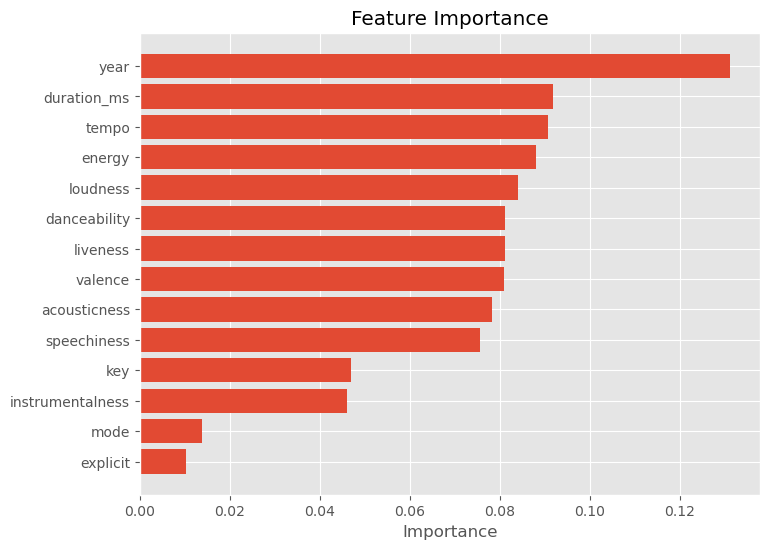

In [113]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.barh(feature_importance["Feature"],
         feature_importance["Importance"])

plt.xlabel("Importance")
plt.title("Feature Importance")
plt.gca().invert_yaxis()

plt.show()

In [114]:
print("="*60)
print("Spotify Song Popularity Prediction Project Completed")
print("="*60)

print(f"Model Accuracy : {accuracy*100:.2f}%")

print("\nTop 5 Important Features:")

print(feature_importance.head())

print("\nProject Successfully Completed.")

Spotify Song Popularity Prediction Project Completed
Model Accuracy : 53.47%

Top 5 Important Features:
        Feature  Importance
13         year    0.131172
9   duration_ms    0.091838
8         tempo    0.090783
1        energy    0.088117
2      loudness    0.083948

Project Successfully Completed.


# Conclusion

This project predicts whether a Spotify song is Popular,
Moderately Popular or Not Popular using Machine Learning.

The dataset was cleaned and preprocessed before training.
A Random Forest Classifier was used for prediction.

The trained model achieved an accuracy of approximately 52%.

The model was saved successfully and tested on new song data.
Feature Importance and Confusion Matrix were also generated for better evaluation.

# Future Scope

- Improve model accuracy using XGBoost or LightGBM.
- Use a larger Spotify dataset.
- Deploy the model using Flask or Streamlit.
- Build a web application for real-time prediction.
- Tune hyperparameters for better performance.